# CIS*4020 — Assignment 1
## Data Wrangling & EDA on the Open University Learning Analytics Dataset (OULAD)

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)          # reproducibility (Part 5)
pd.set_option("display.max_columns", 40)
print("pandas", pd.__version__)

pandas 3.0.6


## Data loading

**Where the data goes:** put the 7 OULAD CSV files in a folder named `content/` next to this notebook
(i.e. `content/studentInfo.csv`, `content/studentVle.csv`, ...). They can be downloaded from the
[UCI repository](https://archive.ics.uci.edu/dataset/349/open+university+learning+analytics+dataset).

**Decision — missing-value marker:** OULAD encodes missing values as `"?"` rather than leaving the field blank
(e.g. `imd_band`, `date_unregistration`, `score`, `week_from`/`week_to`). I pass `na_values="?"` so pandas
reads these as real missing values (`NaN`); otherwise the affected columns would be read as text (`object`)
and both their dtypes and missing-value counts would be wrong.

*Note:* `studentVle.csv` is ~450 MB (~10.6M rows), so loading takes a little while.

In [2]:
DATA_DIR = "content/"   # folder containing the OULAD .csv files (relative to this notebook)

In [3]:
FILES = {"studentInfo":"studentInfo.csv", "studentRegistration":"studentRegistration.csv",
         "studentVle":"studentVle.csv", "vle":"vle.csv", "assessments":"assessments.csv",
         "studentAssessment":"studentAssessment.csv", "courses":"courses.csv"}

def load_oulad():
    missing = [f for f in FILES.values() if not os.path.exists(os.path.join(DATA_DIR, f))]
    if missing:
        raise FileNotFoundError(
            f"Couldn't find these OULAD files in DATA_DIR={DATA_DIR!r}: {missing}. "
            "Set DATA_DIR to the folder containing the CSVs."
        )
    print("[info] loading real OULAD from", DATA_DIR)
    return {k: pd.read_csv(os.path.join(DATA_DIR, f), na_values="?") for k, f in FILES.items()}

tables = load_oulad()
for name, t in tables.items():
    print(f"{name:22s} {t.shape}")

[info] loading real OULAD from content/
studentInfo            (32593, 12)
studentRegistration    (32593, 5)
studentVle             (10655280, 6)
vle                    (6364, 6)
assessments            (206, 6)
studentAssessment      (173912, 5)
courses                (22, 3)


## Part 1 — Acquire & understand

In [4]:
# Inspect studentInfo: shape, column types, first rows and outcome breakdown.
si = tables["studentInfo"]
print("shape (rows, columns):", si.shape)
print("\ncolumn types:")
print(si.dtypes)
print("\nfirst rows:")
display(si.head())
print("outcome breakdown:")
print(si["final_result"].value_counts())

shape (rows, columns): (32593, 12)

column types:
code_module               str
code_presentation         str
id_student              int64
gender                    str
region                    str
highest_education         str
imd_band                  str
age_band                  str
num_of_prev_attempts    int64
studied_credits         int64
disability                str
final_result              str
dtype: object

first rows:


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


outcome breakdown:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


In [5]:
# Attribute-type table: one row per column across all 7 tables.
# The pandas dtype is read from the loaded tables (so it always matches what pandas actually inferred)
ATTRS = [
    # (table, column, attribute_type, why)
    ("studentInfo", "code_module",          "nominal",  "module identifier, categories have no order"),
    ("studentInfo", "code_presentation",    "nominal",  "presentation identifier, used as a label"),
    ("studentInfo", "id_student",           "nominal",  "identifier, arithmetic is meaningless"),
    ("studentInfo", "gender",               "nominal",  "binary category (F/M), no order"),
    ("studentInfo", "region",               "nominal",  "region identifier, no order"),
    ("studentInfo", "highest_education",    "ordinal",  "education levels have a natural order"),
    ("studentInfo", "imd_band",             "ordinal",  "deprivation bands have a natural order"),
    ("studentInfo", "age_band",             "ordinal",  "age bands are ordered but unequal in width"),
    ("studentInfo", "num_of_prev_attempts", "ratio",    "count of attempts, true zero"),
    ("studentInfo", "studied_credits",      "ratio",    "credit count, true zero"),
    ("studentInfo", "disability",           "nominal",  "binary category (Y/N), no order"),
    ("studentInfo", "final_result",         "ordinal",  "Fail < Pass < Distinction are ordered. Withdrawn sits outside that order"),

    ("studentRegistration", "code_module",         "nominal",  "module identifier (join key)"),
    ("studentRegistration", "code_presentation",   "nominal",  "presentation identifier (join key)"),
    ("studentRegistration", "id_student",          "nominal",  "identifier (join key)"),
    ("studentRegistration", "date_registration",   "interval", "day relative to module start, day 0 is an arbitrary origin and values can be negative"),
    ("studentRegistration", "date_unregistration", "interval", "day relative to module start, arbitrary origin"),

    ("studentVle", "code_module",       "nominal",  "module identifier (join key)"),
    ("studentVle", "code_presentation", "nominal",  "presentation identifier (join key)"),
    ("studentVle", "id_student",        "nominal",  "identifier (join key)"),
    ("studentVle", "id_site",           "nominal",  "VLE material identifier (join key to vle)"),
    ("studentVle", "date",              "interval", "day relative to module start, arbitrary origin, can be negative"),
    ("studentVle", "sum_click",         "ratio",    "click count, true zero"),

    ("vle", "id_site",           "nominal",  "VLE material identifier"),
    ("vle", "code_module",       "nominal",  "module identifier"),
    ("vle", "code_presentation", "nominal",  "presentation identifier"),
    ("vle", "activity_type",     "nominal",  "kind of material, no order"),
    ("vle", "week_from",         "interval", "week relative to module start, arbitrary origin"),
    ("vle", "week_to",           "interval", "week relative to module start, arbitrary origin"),

    ("assessments", "code_module",       "nominal",  "module identifier"),
    ("assessments", "code_presentation", "nominal",  "presentation identifier"),
    ("assessments", "id_assessment",     "nominal",  "assessment identifier"),
    ("assessments", "assessment_type",   "nominal",  "type of assessment, no order"),
    ("assessments", "date",              "interval", "deadline as day relative to module start, arbitrary origin"),
    ("assessments", "weight",            "ratio",    "% weight of the assessment, true zero"),

    ("studentAssessment", "id_assessment",  "nominal",  "assessment identifier (join key to assessments)"),
    ("studentAssessment", "id_student",     "nominal",  "identifier"),
    ("studentAssessment", "date_submitted", "interval", "day relative to module start, arbitrary origin"),
    ("studentAssessment", "is_banked",      "nominal",  "binary flag (0/1): result carried over from a previous presentation"),
    ("studentAssessment", "score",          "ratio",    "score 0-100, true zero"),

    ("courses", "code_module",                "nominal", "module identifier"),
    ("courses", "code_presentation",          "nominal", "presentation identifier"),
    ("courses", "module_presentation_length", "ratio",   "length in days; true zero"),
]

attr_types = pd.DataFrame(
    [(t, col, str(tables[t][col].dtype), a_type, why) for t, col, a_type, why in ATTRS],
    columns=["table", "column", "pandas_dtype", "attribute_type", "why"])

# sanity check: every column of every table is classified exactly once
covered = set(zip(attr_types["table"], attr_types["column"]))
expected = {(t, col) for t, df in tables.items() for col in df.columns}
assert covered == expected and len(attr_types) == len(expected), expected ^ covered

with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(attr_types)

,table,column,pandas_dtype,attribute_type,why
0,studentInfo,code_module,str,nominal,"module identifier, categories have no order"
1,studentInfo,code_presentation,str,nominal,"presentation identifier, used as a label"
2,studentInfo,id_student,int64,nominal,"identifier, arithmetic is meaningless"
3,studentInfo,gender,str,nominal,"binary category (F/M), no order"
4,studentInfo,region,str,nominal,"region identifier, no order"
5,studentInfo,highest_education,str,ordinal,education levels have a natural order
6,studentInfo,imd_band,str,ordinal,deprivation bands have a natural order
7,studentInfo,age_band,str,ordinal,age bands are ordered but unequal in width
8,studentInfo,num_of_prev_attempts,int64,ratio,"count of attempts, true zero"
9,studentInfo,studied_credits,int64,ratio,"credit count, true zero"


In [6]:
# Inspect the remaining tables the same way as studentInfo above: shape, columns, dtypes, first rows,
# and what ONE row represents.
ROW_MEANING = {
    "studentRegistration": "one student's registration on one module-presentation",
    "studentVle":          "one student's clicks on one VLE material on one day (the clickstream; many rows per student)",
    "vle":                 "one VLE material (page, quiz, forum, ...) in one module-presentation",
    "assessments":         "one assessment (TMA, CMA or Exam) in one module-presentation",
    "studentAssessment":   "one student's submission/result for one assessment",
    "courses":             "one module-presentation and its length in days",
}

for name, meaning in ROW_MEANING.items():
    t = tables[name]
    print(f"===== {name} =====")
    print("one row =", meaning)
    print("shape (rows, columns):", t.shape)
    print("columns:", list(t.columns))
    print("\ncolumn types:")
    print(t.dtypes)
    print("\nfirst rows:")
    display(t.head())

===== studentRegistration =====
one row = one student's registration on one module-presentation
shape (rows, columns): (32593, 5)
columns: ['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']

column types:
code_module                str
code_presentation          str
id_student               int64
date_registration      float64
date_unregistration    float64
dtype: object

first rows:


,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0
3,AAA,2013J,31604,-52.0,NaN
4,AAA,2013J,32885,-176.0,NaN


===== studentVle =====
one row = one student's clicks on one VLE material on one day (the clickstream; many rows per student)
shape (rows, columns): (10655280, 6)
columns: ['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']

column types:
code_module            str
code_presentation      str
id_student           int64
id_site              int64
date                 int64
sum_click            int64
dtype: object

first rows:


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


===== vle =====
one row = one VLE material (page, quiz, forum, ...) in one module-presentation
shape (rows, columns): (6364, 6)
columns: ['id_site', 'code_module', 'code_presentation', 'activity_type', 'week_from', 'week_to']

column types:
id_site                int64
code_module              str
code_presentation        str
activity_type            str
week_from            float64
week_to              float64
dtype: object

first rows:


...

,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0


===== studentAssessment =====
one row = one student's submission/result for one assessment
shape (rows, columns): (173912, 5)
columns: ['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

column types:
id_assessment       int64
id_student          int64
date_submitted      int64
is_banked           int64
score             float64
dtype: object

first rows:


,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0


===== courses =====
one row = one module-presentation and its length in days
shape (rows, columns): (22, 3)
columns: ['code_module', 'code_presentation', 'module_presentation_length']

column types:
code_module                     str
code_presentation               str
module_presentation_length    int64
dtype: object

first rows:


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240


**Data Description**

OULAD describes student registration across 7 online modules (22 module presentations) at the Open University.

**What each table represents**

- studentInfo - who the students are and how they finished each module.
- studentRegistration - when students registered for a module, and when they unregistered if they dropped out.
- studentVle - students' activity on the VLE, how often they clicked on course materials and on which days.
- vle - the online course materials, when in the module they are meant to be used.
- assessments - the assessments in each module with their deadlines and weights.
- studentAssessment - Students' results on the assessments, when they submitted and what their score was.
- courses - modules and their presentations, along with how long each runs.

**How the tables relate (the keys)**

- studentInfo, studentRegistration and studentVle share the key (code_module, code_presentation, id_student)
- courses, assessments and vle are keyed by (code_module, code_presentation), plus id_assessment / id_site.
- studentAssessment has no module columns. It links to assessments through id_assessment.
- studentVle links to vle through id_site (+ module and presentation).

**Where the data comes from**

The data comes from The Open University (UK) and was donated in December 2015 by Jakub Kuzilek, Martin Hlosta and Zdenek Zdrahal of the Knowledge Media Institute.

**Limitations of the data**

- sum_click counts interactions, not time spent or understanding material.
- Dates are relative to the module start and are not calendar dates.
- Data has a narrow scope, so results may not generalise to other institutions, years or in-person teaching.

## Part 2 — Clean & prepare

### 2a. Aggregate the clickstream to one row per student

In [7]:
# Total clicks and number of active days per student.
KEYS = ["code_module", "code_presentation", "id_student"]   # the join keys
vle_long = tables["studentVle"]

engagement = (vle_long
    .groupby(KEYS)                       # one group per student-module
    .agg(total_clicks=("sum_click", "sum"),     # add up all clicks
         active_days=("date", "nunique"))       # count distinct days they were active
    .reset_index())                      # turn the group keys back into columns
engagement.head()

,code_module,code_presentation,id_student,total_clicks,active_days
0,AAA,2013J,11391,934,40
1,AAA,2013J,28400,1435,80
2,AAA,2013J,30268,281,12
3,AAA,2013J,31604,2158,123
4,AAA,2013J,32885,1034,70


In [8]:
# Part 2a: add an "early engagement" feature = clicks before day 30.
# Step 1: filter the clickstream to early days
early = vle_long[vle_long["date"] < 30]

# Step 2: group + sum
early_engagement = early.groupby(KEYS).agg(early_clicks=("sum_click", "sum")).reset_index()

# Step 3: merge it onto `engagement` (how="left")
engagement = engagement.merge(early_engagement, on=KEYS, how="left")

### 2b. Join everything into one analysis table (one row per student-module)

In [9]:
# Start the analysis table: studentInfo + engagement (left join keeps every student).
analysis = tables["studentInfo"].merge(engagement, on=KEYS, how="left")

# students absent from the VLE -> NaN engagement -> fill with 0 (flag them first so we don't lose info)
analysis["no_vle_activity"] = analysis["total_clicks"].isna()
for c in ["total_clicks", "active_days"]:
    analysis[c] = analysis[c].fillna(0)

# outcome flags for later EDA
analysis["withdrew"] = analysis["final_result"].eq("Withdrawn")
analysis["passed"]   = analysis["final_result"].isin(["Pass", "Distinction"])

print("analysis table shape:", analysis.shape)
analysis.head()

analysis table shape: (32593, 18)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks,active_days,early_clicks,no_vle_activity,withdrew,passed
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,934.0,40.0,419.0,False,False,True
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,1435.0,80.0,618.0,False,False,True
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,281.0,12.0,281.0,False,True,False
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,2158.0,123.0,503.0,False,False,True
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,1034.0,70.0,567.0,False,False,True


In [10]:
# Part 2b: enrich the analysis table.
#   - merge in registration info: tables["studentRegistration"] on KEYS (how="left")
analysis = analysis.merge(tables["studentRegistration"], on=KEYS, how="left")

### 2c. Missing data — handle each variable *deliberately*

In [11]:
# See what's missing, and handle imd_band by keep-and-flag.
print("missing values per column:")
print(analysis.isna().sum()[analysis.isna().sum() > 0].to_string() or "  (none)")

analysis["imd_band"]    = analysis["imd_band"].replace({"10-20": "10-20%"})  # fix a known formatting quirk
analysis["imd_missing"] = analysis["imd_band"].isna()                        # flag, don't silently drop
analysis["imd_band"]    = analysis["imd_band"].fillna("Missing")             # keep as its own category
print("\nIMD missing kept as a 'Missing' category:", int(analysis["imd_missing"].sum()), "students")

missing values per column:
imd_band                1111
early_clicks            3778
date_registration         45
date_unregistration    22521

IMD missing kept as a 'Missing' category: 1111 students


In [12]:
# Part 2c: handle date_unregistration as INFORMATIVE.
#   - date_unregistration is missing because it is not applicable to all cases (the student never unregistered), so it is
#     kept as NaN (not imputed) and turned into a flag.
analysis["unregistered"] = analysis["date_unregistration"].notna()

#   - sanity-check it against final_result == "Withdrawn" (they should mostly agree).
print("unregistered vs final_result:")
print(pd.crosstab(analysis["final_result"], analysis["unregistered"]))

#   - date_registration has a few gaps: keep-and-flag (no imputation, since the gaps are tied to the outcome).
analysis["registration_missing"] = analysis["date_registration"].isna()
print("\nmissing date_registration:", int(analysis["registration_missing"].sum()), "students; outcomes:")
print(analysis.loc[analysis["registration_missing"], "final_result"].value_counts().to_string())

#   - early_clicks: NaN means no clicks before day 30 (incl. students with no VLE activity at all) -> 0.
analysis["early_clicks"] = analysis["early_clicks"].fillna(0)

unregistered vs final_result:
unregistered  False  True 
final_result              
Distinction    3024      0
Fail           7043      9
Pass          12361      0
Withdrawn        93  10063

missing date_registration: 45 students; outcomes:
final_result
Withdrawn    39
Fail          5
Pass          1


**imd_band**

- This missing data indicates that the deprivation band was not recorded for those students.
- To deal with this, a new category "Missing" is made, plus an imd_missing flag.
- Dropping this data would lose these students and a constant category can distort statistics, so "missing" is left off the IMD trend.

**date_unregistration**

- This missing data indicates that this attribute does not apply to all students, as some students never unregistered. So there would be no unregistration date.
- To deal with this, an unregistered flag is set but the missing values are ignored during analysis.
- Any filled in date would imply an unregistration that never happened.

**date_registration**

- This missing data indicates that the registration was not recorded.
- To deal with this, a registration_missing flag is set but the missing values are ignored during analysis.
- 39 of the 45 students with no registration date withdrew, so the missing data is not random. So dropping them would hide that correlation.

**total_clicks, active_days, early_clicks**

- Not truly missing data: a NaN means the student has no clickstream rows in that window. 3,365 students have no VLE rows at all, and another 413 only have activity from day 30 onwards, so they have no early_clicks.
- To deal with this, fill with 0. The no_vle_activity flag (set before filling) marks the 3,365 students with no VLE records at all.
- 0 is the actual recorded value (no clicks before day 30, or no clicks at all), and the flag keeps track of the students who never used the VLE.

### 2d. Outliers & inconsistencies

In [13]:
# Look for extreme click counts with the IQR rule.
print(analysis["total_clicks"].describe())
q1, q3 = analysis["total_clicks"].quantile([0.25, 0.75]); iqr = q3 - q1
fence = q3 + 1.5*iqr
print(f"\nIQR upper fence = {fence:.0f}; students above it = {(analysis['total_clicks'] > fence).sum()}")

count    32593.000000
mean      1215.141257
std       1692.604449
min          0.000000
25%        142.000000
50%        602.000000
75%       1585.000000
max      24139.000000
Name: total_clicks, dtype: float64

IQR upper fence = 3750; students above it = 2503


In [14]:
# Part 2d: outliers and inconsistencies.
#   Are extreme click counts errors, or just very engaged students? Look at who is above the IQR fence.
high_clicks = analysis["total_clicks"] > fence
print("students above the IQR fence - engagement:")
print(analysis.loc[high_clicks, ["total_clicks", "active_days"]].describe().round(1).to_string())
print("\nstudents above the IQR fence - outcomes:")
print(analysis.loc[high_clicks, "final_result"].value_counts(normalize=True).round(3).to_string())
# -> decision: KEEP (no capping/removal); these are active students, not errors. Skew is handled with log axes in Part 3.

#   Check for impossible values and inconsistent categories.
# (1) impossible dates
last_click = (vle_long.groupby(["code_module", "code_presentation"])["date"].max().reset_index()
              .merge(tables["courses"], on=["code_module", "code_presentation"]))
print("\nmodule-presentations with clicks after the module ended:",
      int((last_click["date"] > last_click["module_presentation_length"]).sum()))
print("unregistered before registering:", int((analysis["date_unregistration"] < analysis["date_registration"]).sum()))
print("unregistered on/before day 0 (left by the module start):", int((analysis["date_unregistration"] <= 0).sum()))
print("registered after day 0 (late registration):", int((analysis["date_registration"] > 0).sum()))
print("early_clicks > total_clicks:", int((analysis["early_clicks"] > analysis["total_clicks"]).sum()))

# (2) ranges of the other numeric variables
print("\nnumeric ranges:")
print(analysis[["num_of_prev_attempts", "studied_credits", "active_days", "early_clicks"]].describe().loc[["min", "max"]].to_string())

# (3) inconsistent categories (imd_band "10-20" was already fixed in 2c)
print("\ncategory values:")
for col in ["gender", "region", "highest_education", "imd_band", "age_band", "disability", "final_result"]:
    print(f"  {col}: {sorted(analysis[col].unique())}")

students above the IQR fence - engagement:
       total_clicks  active_days
count        2503.0       2503.0
mean         5763.5        166.6
std          2243.4         44.4
min          3750.0         52.0
25%          4334.0        135.0
50%          5037.0        164.0
75%          6381.0        197.0
max         24139.0        286.0

students above the IQR fence - outcomes:
final_result
Pass           0.628
Distinction    0.304
Fail           0.052
Withdrawn      0.016

module-presentations with clicks after the module ended: 0
unregistered before registering: 0
unregistered on/before day 0 (left by the module start): 3097
registered after day 0 (late registration): 234
early_clicks > total_clicks: 0

numeric ranges:
     num_of_prev_attempts  studied_credits  active_days  early_clicks
min                   0.0             30.0          0.0           0.0
max                   6.0            655.0        286.0        7926.0

category values:
  gender: ['F', 'M']
  region: ['East An

**Outliers in total clicks**

- Outliers were found using the IQR rule. 2,503 students are above the upper fence of 3,750 clicks, with the highest being 24,139 clicks.
- These students used the VLE on about 167 distinct days on average, so their high click counts come from consistent use.
- 62.8% passed and 30.4% earned a distinction, which is consistent with very engaged students.
- These students were kept, as removing them would discard the most engaged group of students, and capping their click counts would remove real differences between students.


## Part 3 — Explore (EDA)

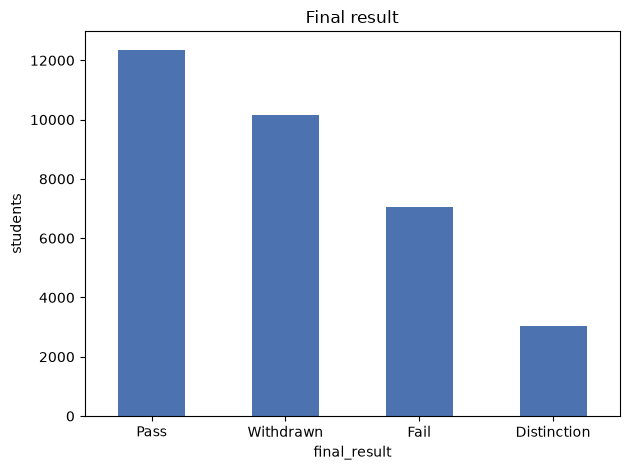

In [15]:
# Bar chart of outcomes.
analysis["final_result"].value_counts().plot(kind="bar", color="#4C72B0")
plt.title("Final result"); plt.ylabel("students"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

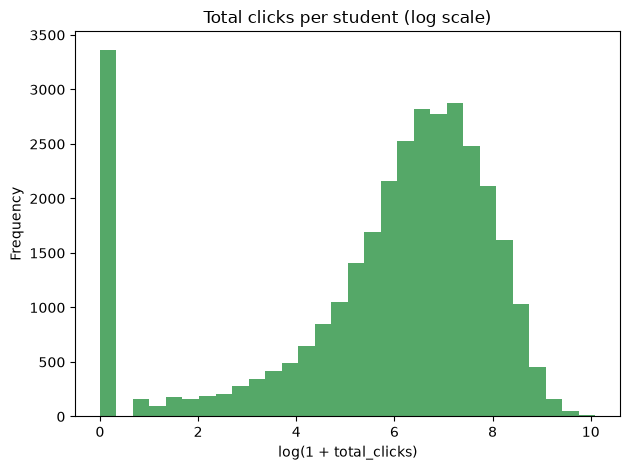

In [16]:
# Histogram of total clicks (engagement is very skewed -> use a log axis).
np.log1p(analysis["total_clicks"]).plot(kind="hist", bins=30, color="#55A868")
plt.title("Total clicks per student (log scale)"); plt.xlabel("log(1 + total_clicks)")
plt.tight_layout(); plt.show()

In [17]:
# (a) pass rate by IMD band
pass_rate_by_imd = analysis.groupby("imd_band")["passed"].mean()
print("pass rate by IMD band:"); print(pass_rate_by_imd.round(3).to_string())

# (b) outcome mix by disability (proportions)
print("\noutcome mix by disability:")
print(pd.crosstab(analysis["disability"], analysis["final_result"], normalize="index").round(2))

# (c) mean total clicks by outcome
print("\nmean total_clicks by outcome:")
print(analysis.groupby("final_result")["total_clicks"].mean().round(1).to_string())

pass rate by IMD band:
imd_band
0-10%      0.352
10-20%     0.386
20-30%     0.407
30-40%     0.469
40-50%     0.466
50-60%     0.488
60-70%     0.519
70-80%     0.515
80-90%     0.541
90-100%    0.575
Missing    0.657

outcome mix by disability:
final_result  Distinction  Fail  Pass  Withdrawn
disability                                      
N                    0.10  0.22  0.39       0.30
Y                    0.07  0.23  0.31       0.39

mean total_clicks by outcome:
final_result
Distinction    2666.8
Fail            651.9
Pass           1921.8
Withdrawn       314.0


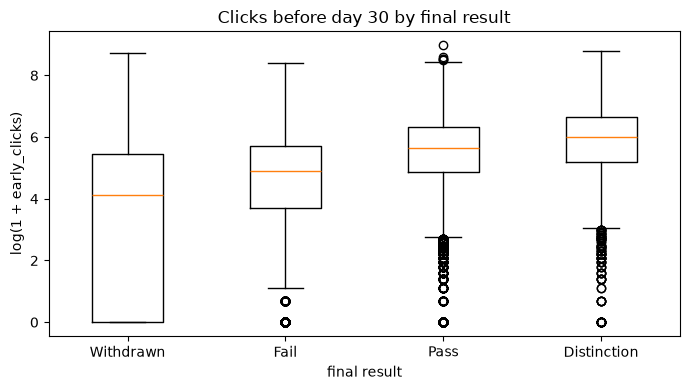

early_clicks by final result:
                  n  median   mean
final_result                      
Withdrawn     10156    60.0  173.6
Fail           7052   134.0  228.6
Pass          12361   286.0  418.9
Distinction    3024   403.5  581.5


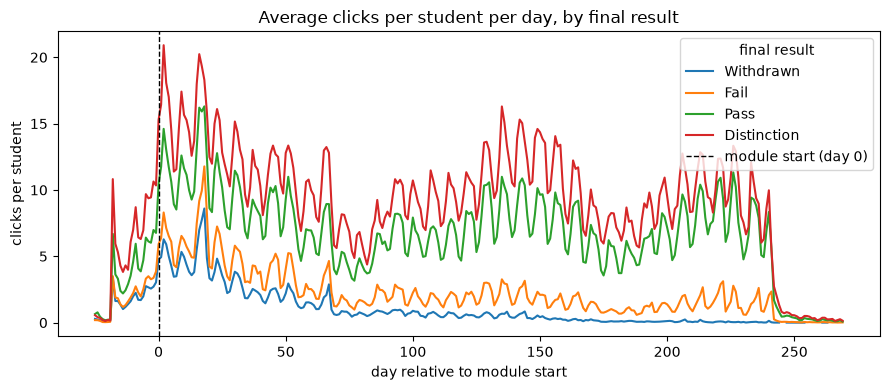

average daily clicks per student, before vs after the module start:
              before day 0  day 0 onwards
final_result                             
Withdrawn             1.51           1.07
Fail                  1.77           2.25
Pass                  3.41           6.80
Distinction           5.26           9.39


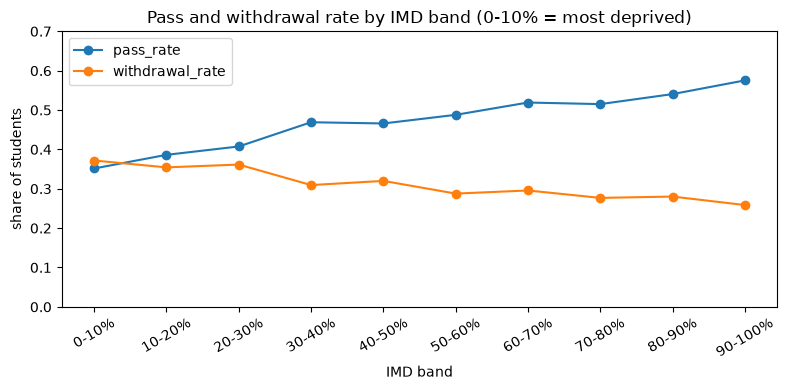

outcome rates by IMD band:
             n  pass_rate  withdrawal_rate
imd_band                                  
0-10%     3311      0.352            0.372
10-20%    3516      0.386            0.354
20-30%    3654      0.407            0.362
30-40%    3539      0.469            0.309
40-50%    3256      0.466            0.320
50-60%    3124      0.488            0.288
60-70%    2905      0.519            0.296
70-80%    2879      0.515            0.277
80-90%    2762      0.541            0.280
90-100%   2536      0.575            0.259
Missing   1111      0.657            0.212


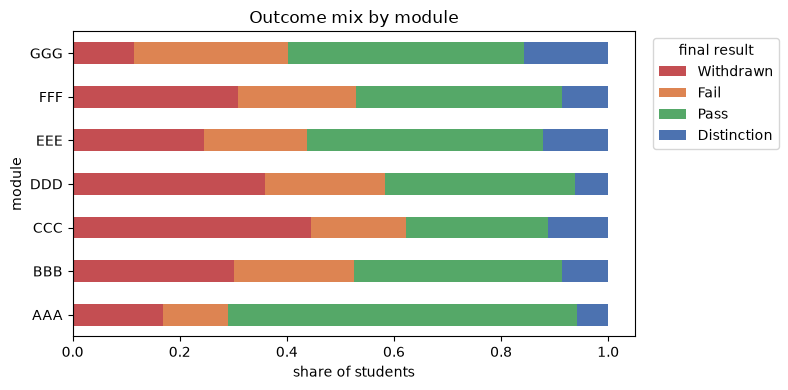

outcome mix by module:
final_result  Withdrawn   Fail   Pass  Distinction     n
code_module                                             
AAA               0.168  0.122  0.651        0.059   748
BBB               0.302  0.223  0.389        0.086  7909
CCC               0.445  0.176  0.266        0.112  4434
DDD               0.359  0.225  0.355        0.061  6272
EEE               0.246  0.192  0.441        0.121  2934
FFF               0.310  0.220  0.384        0.086  7762
GGG               0.115  0.287  0.441        0.156  2534


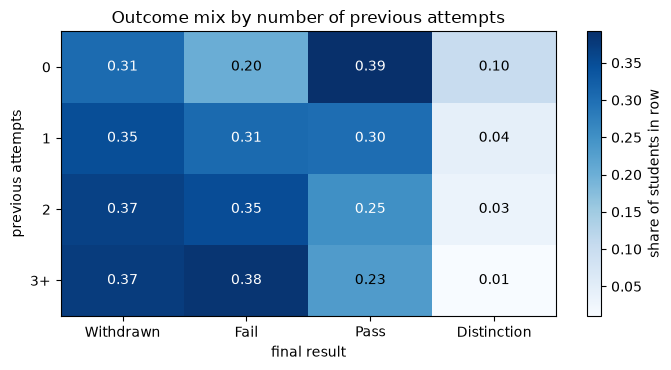

outcome mix by previous attempts:
final_result          Withdrawn   Fail   Pass  Distinction      n
num_of_prev_attempts                                             
0                         0.306  0.202  0.392        0.101  28421
1                         0.349  0.306  0.302        0.043   3299
2                         0.366  0.350  0.252        0.033    675
3+                        0.374  0.384  0.232        0.010    198


In [18]:
# Part 3: five varied visualizations, each followed by its summary statistics.
OUTCOME_ORDER = ["Withdrawn", "Fail", "Pass", "Distinction"]
# note: "Withdrawn" includes 3,089 students who unregistered on/before day 0, which pulls that group's engagement down.

# ---------------------------------------------------------------------------------------------
# 1) Comparison: early engagement vs final outcome (box plot; log scale because clicks are very skewed)
groups = [np.log1p(analysis.loc[analysis["final_result"] == r, "early_clicks"]) for r in OUTCOME_ORDER]
plt.figure(figsize=(7, 4))
plt.boxplot(groups, tick_labels=OUTCOME_ORDER)
plt.title("Clicks before day 30 by final result"); plt.xlabel("final result"); plt.ylabel("log(1 + early_clicks)")
plt.tight_layout(); plt.show()
print("early_clicks by final result:")
print(analysis.groupby("final_result")["early_clicks"].agg(n="size", median="median", mean="mean")
      .reindex(OUTCOME_ORDER).round(1).to_string())

# ---------------------------------------------------------------------------------------------
# 2) Over time: clicks per day. A raw total mostly reflects how many students are in each group,
#    so the total for each outcome is divided by the number of students with that outcome.
vle_outcome = vle_long.merge(analysis[KEYS + ["final_result"]], on=KEYS, how="left")
daily_clicks = vle_outcome.groupby(["date", "final_result"])["sum_click"].sum().unstack()[OUTCOME_ORDER]
students_per_outcome = analysis["final_result"].value_counts()[OUTCOME_ORDER]
clicks_per_student = daily_clicks / students_per_outcome

clicks_per_student.plot(figsize=(9, 4))
plt.axvline(0, color="k", ls="--", lw=1, label="module start (day 0)")
plt.title("Average clicks per student per day, by final result")
plt.xlabel("day relative to module start"); plt.ylabel("clicks per student"); plt.legend(title="final result")
plt.tight_layout(); plt.show()
print("average daily clicks per student, before vs after the module start:")
print(pd.DataFrame({"before day 0": clicks_per_student[clicks_per_student.index < 0].mean(),
                    "day 0 onwards": clicks_per_student[clicks_per_student.index >= 0].mean()}).round(2).to_string())

# ---------------------------------------------------------------------------------------------
# 3) Equity: pass / withdrawal rate by imd_band (ordinal -> keep the bands in their natural order)
IMD_ORDER = ["0-10%", "10-20%", "20-30%", "30-40%", "40-50%", "50-60%", "60-70%", "70-80%", "80-90%", "90-100%", "Missing"]
analysis["imd_band"] = pd.Categorical(analysis["imd_band"], categories=IMD_ORDER, ordered=True)
imd_rates = analysis.groupby("imd_band", observed=True).agg(
    n=("passed", "size"), pass_rate=("passed", "mean"), withdrawal_rate=("withdrew", "mean"))

# "Missing" is not a point on the deprivation scale, so it is left out of the line (but reported in the table)
imd_rates.drop("Missing")[["pass_rate", "withdrawal_rate"]].plot(marker="o", figsize=(8, 4))
plt.title("Pass and withdrawal rate by IMD band (0-10% = most deprived)")
plt.xlabel("IMD band"); plt.ylabel("share of students"); plt.xticks(range(10), IMD_ORDER[:-1], rotation=30)
plt.ylim(0, 0.7)   # start the axis at 0 so the gap between bands is not exaggerated
plt.tight_layout(); plt.show()
print("outcome rates by IMD band:")
print(imd_rates.round(3).to_string())

# ---------------------------------------------------------------------------------------------
# 4) Composition: outcome mix by module (100% stacked bars, so modules of different sizes are comparable)
module_mix = pd.crosstab(analysis["code_module"], analysis["final_result"], normalize="index")[OUTCOME_ORDER]
module_mix.plot(kind="barh", stacked=True, figsize=(8, 4), color=["#C44E52", "#DD8452", "#55A868", "#4C72B0"])
plt.title("Outcome mix by module"); plt.xlabel("share of students"); plt.ylabel("module")
plt.legend(title="final result", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()
print("outcome mix by module:")
print(module_mix.round(3).assign(n=analysis["code_module"].value_counts()).to_string())

# ---------------------------------------------------------------------------------------------
# 5) Prior attempts vs outcome (contingency heatmap, row-normalized). 3+ attempts are grouped because
#    each of those groups has fewer than 150 students.
prev_attempts = analysis["num_of_prev_attempts"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
attempts_mix = pd.crosstab(prev_attempts, analysis["final_result"], normalize="index")[OUTCOME_ORDER]

fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(attempts_mix.values, cmap="Blues", aspect="auto")
fig.colorbar(im, label="share of students in row")
ax.set_xticks(range(len(OUTCOME_ORDER))); ax.set_xticklabels(OUTCOME_ORDER)
ax.set_yticks(range(len(attempts_mix))); ax.set_yticklabels(attempts_mix.index)
for (i, j), v in np.ndenumerate(attempts_mix.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.25 else "black")
ax.set_xlabel("final result"); ax.set_ylabel("previous attempts")
ax.set_title("Outcome mix by number of previous attempts")
plt.tight_layout(); plt.show()
print("outcome mix by previous attempts:")
print(attempts_mix.round(3).assign(n=prev_attempts.value_counts()).to_string())

## Part 4 — Findings (with a social lens)

In [19]:
# Withdrawal rate by IMD band.
wr = analysis.groupby("imd_band")["withdrew"].mean().round(3)
print("withdrawal rate by IMD band:"); print(wr.to_string())

withdrawal rate by IMD band:
imd_band
0-10%      0.372
10-20%     0.354
20-30%     0.362
30-40%     0.309
40-50%     0.320
50-60%     0.288
60-70%     0.296
70-80%     0.277
80-90%     0.280
90-100%    0.259
Missing    0.212


1. **Finding:** Students who engage more before day 30 have a higher chance of passing

    - *evidence: median early clicks rise from 60 (Withdrawn) to 134 (Fail), 286 (Pass) and 403.5 (Distinction) in "Clicks before day 30 by final result"; from day 0 onwards, Pass students average 6.80 clicks per day vs 1.07 for Withdrawn students in "Average clicks per student per day, by final result"*

    - caveat: this is an association, not proof that clicking causes passing. Motivation, prior knowledge or available study time could be the driver for both. The Withdrawn group also includes 3,089 students who unregistered on or before day 0, which pulls module engagement down.

2. **Finding:** Withdrawal rates differ greatly between modules

    - *evidence: withdrawal ranges from 11.5% in GGG to 44.5% in CCC in "Outcome mix by module"*

    - caveat: modules differ in subject, length, assessment design and who enrolls, so the gap may reflect course design or student mix rather than "harder" modules.

3. **Finding (equity):** Students who declared a disability pass less often and withdraw more often

    - *evidence: about 38% of students with a declared disability pass (7.1% Distinction + 31.1% Pass) vs about 48% of those without (9.5% + 38.7%), and 39% withdraw vs 30% in the "outcome mix by disability" cross-tab*

    - caveat: "disability" is self-declared and covers very different needs, so it is a coarse measure. The gap may reflect how accessible the course materials and support are, not students' ability.

## Part 5 — Reproducibility

The notebook runs top to bottom on a clean kernel (Kernel → Restart & Run All) with no errors.

- **Data location:** place the 7 OULAD CSV files in a folder named `content/` next to the notebook (`DATA_DIR = "content/"`), e.g. `content/studentInfo.csv`, `content/studentVle.csv`. They can be downloaded from the [UCI repository](https://archive.ics.uci.edu/dataset/349/open+university+learning+analytics+dataset).

- **Missing values:** files are read with `na_values="?"`, because OULAD codes missing values as `"?"`.

- **Random seed:** `RANDOM_SEED = 42` is set with `np.random.seed` in the setup cell. No step in the analysis is random, so results are identical on every run.

- **Order matters:** later cells reuse variables from earlier ones (e.g. `fence` in 2d, `analysis` throughout), so run all cells in order rather than individually.

- **Environment:** Python 3.14 with pandas 3.0, NumPy and Matplotlib. `studentVle.csv` is about 450 MB, so loading takes a little while.

## Generative-AI disclosure

**Use of generative AI.** Generative AI was used in this assignment. It was used only for the coding sections, all markdown findings and discussions were written by me.
For the code, AI was used as an auto-complete tool to complete lines or small snippets. Also, it was used to generate skeleton code like the code in part 1. I then filled in
the rest of the code by myself. (ex filling in attribute types and why in part 1). I understand and can explain everything in this notebook.